# 02 - Seasonal outlook: will the next 3 months be below normal?
At the end of each month we predict whether the next 3 months' rainfall falls in the **driest third** of history for that season.

**No-leakage rules** (enforced in `sentinel/outlook.py`, tested in `tests/test_outlook_leakage.py`):
1. Time split - the test set is every issue whose target starts in the last 8 complete years; training targets must end before that (purged gap).
2. All normals, standard deviations and tercile thresholds come from training months only.
3. ONI is the season ending the previous month (centred two months back) and DMI is last month's value - what was published at issue time.
4. Model type and warning threshold are chosen on the last 5 training years, never on the test years.
5. Outlooks are not issued for dry-season targets (3-month normal < 30 mm) where 'driest third' is meaningless.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sentinel import config as C
OUT, RAW = C.OUT_DIR, C.RAW_DIR
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
csv = lambda n, **k: pd.read_csv(OUT / n, **k)
summary = json.loads((OUT / "run_summary.json").read_text())
print("Daily data:", summary["daily_range"], "| built", summary["built_utc"])

Daily data: ['1991-01-01', '2026-11-05'] | built 2026-11-13T06:35:47+00:00


In [2]:
info = json.loads((OUT / "outlook_info.json").read_text()); print(json.dumps(info, indent=1))

{
 "split": {
  "test_start": "2018-01-01",
  "last_month": "2026-10-01",
  "last_complete_year": 2025
 },
 "selection": {
  "chosen": "gbm",
  "threshold": 0.34,
  "candidates": {
   "logistic": {
    "brier": 0.21859803452926965,
    "best_threshold": 0.34,
    "best_f1": 0.5042016806722689
   },
   "gbm": {
    "brier": 0.21654890453317685,
    "best_threshold": 0.34,
    "best_f1": 0.46942800788954636
   }
  },
  "source": "inline selection",
  "inner_train_end": "2013-01-01",
  "n_inner_train": 3260,
  "n_inner_valid": 723
 },
 "stats_window": {
  "stats_from": "1991-01-01",
  "stats_to": "2017-12-01",
  "train_end_exclusive": "2018-01-01"
 },
 "n_train": 4010,
 "n_test": 1295,
 "features": [
  "rain_z_1m",
  "rain_z_3m",
  "tmean_anom_3m",
  "oni_lag",
  "oni_change_3m",
  "dmi_lag",
  "target_month_sin",
  "target_month_cos",
  "log_clim_target_mm",
  "zone"
 ],
 "model_source": "inline selection",
 "train_issue_range": [
  "1991-01-01",
  "2017-09-01"
 ],
 "test_issue_range": [

## Per-county results on the test years
Baselines: **climatology** (always 33%; as a categorical forecast, a random 1-in-3 warning, so precision = observed base rate and recall = 1/3) and **persistence** (dry last 3 months -> predict dry).

In [3]:
met = csv("outlook_metrics.csv")
cols = ["county", "n_test", "observed_below_rate", "model_precision", "model_recall", "model_f1", "persistence_precision",
        "persistence_recall", "persistence_f1", "climatology_f1", "brier_model", "brier_persistence", "brier_climatology",
        "bss_model_vs_clim", "bss_90ci_lo", "bss_90ci_hi", "bss_persistence_vs_clim", "roc_auc_model", "verdict"]
met[cols].round(3)

,county,n_test,observed_below_rate,model_precision,model_recall,model_f1,persistence_precision,persistence_recall,persistence_f1,climatology_f1,brier_model,brier_persistence,brier_climatology,bss_model_vs_clim,bss_90ci_lo,bss_90ci_hi,bss_persistence_vs_clim,roc_auc_model,verdict
0,Busia,104,0.365,0.353,0.316,0.333,0.351,0.342,0.347,0.349,0.264,0.236,0.233,-0.135,-0.284,0.007,-0.012,0.531,No skill - use climatology
1,Garissa,68,0.338,0.379,0.478,0.423,0.217,0.217,0.217,0.336,0.234,0.234,0.224,-0.044,-0.217,0.098,-0.044,0.591,No skill - use climatology
2,Kilifi,104,0.202,0.222,0.381,0.281,0.318,0.333,0.326,0.251,0.180,0.173,0.178,-0.006,-0.122,0.093,0.030,0.572,No skill - use climatology
3,Kisumu,104,0.135,0.100,0.214,0.136,0.000,0.000,0.000,0.192,0.162,0.155,0.156,-0.037,-0.181,0.133,0.005,0.467,No skill - use climatology
4,Kwale,104,0.240,0.306,0.440,0.361,0.423,0.440,0.431,0.279,0.187,0.183,0.191,0.020,-0.115,0.133,0.041,0.617,Weak or uncertain skill
5,Lamu,104,0.288,0.324,0.400,0.358,0.303,0.333,0.317,0.309,0.206,0.209,0.207,0.006,-0.146,0.131,-0.006,0.611,Weak or uncertain skill
6,Makueni,86,0.465,0.606,0.500,0.548,0.590,0.575,0.582,0.388,0.269,0.254,0.266,-0.011,-0.157,0.103,0.046,0.675,No skill - use climatology
7,Mandera,69,0.493,0.609,0.412,0.491,0.536,0.441,0.484,0.398,0.285,0.271,0.275,-0.035,-0.135,0.050,0.016,0.650,No skill - use climatology
8,Marsabit,77,0.429,0.484,0.455,0.469,0.389,0.424,0.406,0.375,0.256,0.257,0.254,-0.006,-0.132,0.125,-0.012,0.652,No skill - use climatology
9,Mombasa,104,0.240,0.306,0.440,0.361,0.269,0.280,0.275,0.279,0.188,0.191,0.191,0.016,-0.096,0.101,0.003,0.617,Weak or uncertain skill


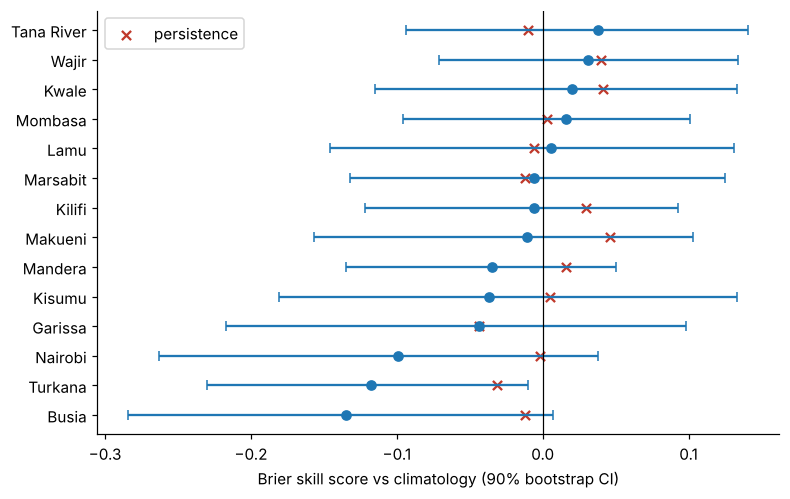

In [4]:
m = met[met.county != "ALL (pooled)"].sort_values("bss_model_vs_clim")
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(m.bss_model_vs_clim, m.county, xerr=[m.bss_model_vs_clim - m.bss_90ci_lo, m.bss_90ci_hi - m.bss_model_vs_clim], fmt="o", capsize=3)
ax.scatter(m.bss_persistence_vs_clim, m.county, marker="x", color="#c0392b", label="persistence")
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Brier skill score vs climatology (90% bootstrap CI)"); ax.legend()

## By target season (all counties pooled)
The Indian Ocean Dipole is a known driver of the Oct-Dec short rains, so skill is expected there before Mar-May.

In [5]:
csv("outlook_by_season.csv").round(3)

,target_season,n_test,bss_model,bss_90ci,bss_persistence,model_f1,persistence_f1
0,MAM (issued end Feb),126,0.049,"[-0.23, 0.25]",-0.041,0.477,0.286
1,OND (issued end Sep),112,0.098,"[-0.04, 0.31]",0.012,0.377,0.316


## Reliability: are the probabilities honest?

,forecast,observed,n
bin,,,
"(-0.001, 0.2]",0.077,0.266,463
"(0.2, 0.4]",0.303,0.312,513
"(0.4, 0.6]",0.467,0.362,298
"(0.6, 0.8]",0.657,0.619,21


Text(0, 0.5, 'observed frequency')

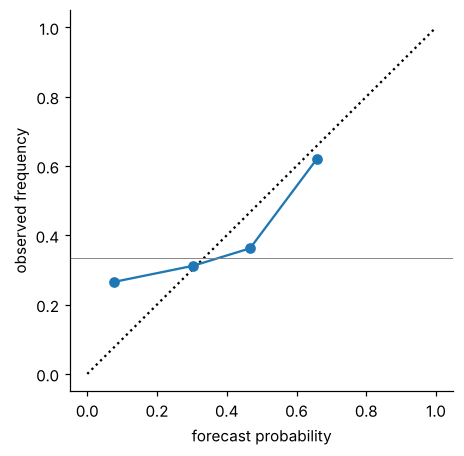

In [6]:
te = pd.read_parquet(OUT / "outlook_test_predictions.parquet")
bins = np.linspace(0, 1, 6); te["bin"] = pd.cut(te.p_model, bins, include_lowest=True)
rel = te.groupby("bin", observed=True).agg(forecast=("p_model", "mean"), observed=("y", "mean"), n=("y", "size"))
display(rel.round(3))
fig, ax = plt.subplots(figsize=(4.5, 4.5)); ax.plot([0, 1], [0, 1], "k:"); ax.plot(rel.forecast, rel.observed, "o-")
ax.axhline(1/3, color="grey", lw=0.6); ax.set_xlabel("forecast probability"); ax.set_ylabel("observed frequency")

## Plain statement of skill

In [7]:
for r in met.itertuples():
    ci = f"BSS {r.bss_model_vs_clim:+.2f} (90% CI {r.bss_90ci_lo:+.2f} to {r.bss_90ci_hi:+.2f})"
    print(f"- {r.county}: {r.verdict}. {ci}; F1 model {r.model_f1:.2f} vs persistence {r.persistence_f1:.2f} vs climatology {r.climatology_f1:.2f}.")
ns = met[(met.county != "ALL (pooled)") & met.verdict.str.startswith("No skill")].county.tolist()
print(f"\nWhere there is no skill ({', '.join(ns) or 'none'}), the dashboard and agent publish the climatological 33% instead of the model.")

- Busia: No skill - use climatology. BSS -0.14 (90% CI -0.28 to +0.01); F1 model 0.33 vs persistence 0.35 vs climatology 0.35.
- Garissa: No skill - use climatology. BSS -0.04 (90% CI -0.22 to +0.10); F1 model 0.42 vs persistence 0.22 vs climatology 0.34.
- Kilifi: No skill - use climatology. BSS -0.01 (90% CI -0.12 to +0.09); F1 model 0.28 vs persistence 0.33 vs climatology 0.25.
- Kisumu: No skill - use climatology. BSS -0.04 (90% CI -0.18 to +0.13); F1 model 0.14 vs persistence 0.00 vs climatology 0.19.
- Kwale: Weak or uncertain skill. BSS +0.02 (90% CI -0.12 to +0.13); F1 model 0.36 vs persistence 0.43 vs climatology 0.28.
- Lamu: Weak or uncertain skill. BSS +0.01 (90% CI -0.15 to +0.13); F1 model 0.36 vs persistence 0.32 vs climatology 0.31.
- Makueni: No skill - use climatology. BSS -0.01 (90% CI -0.16 to +0.10); F1 model 0.55 vs persistence 0.58 vs climatology 0.39.
- Mandera: No skill - use climatology. BSS -0.04 (90% CI -0.14 to +0.05); F1 model 0.49 vs persistence 0.48 vs c

## Live outlook (issued at the end of the latest complete month)

In [8]:
csv("outlook_live.csv")

,county,issued_end_of,target_months,prob_below_normal,model_raw_prob,basis,backtest_verdict,confidence,bss_backtest,below_normal_threshold_mm,normal_mm,oni_used,dmi_used,inputs_missing
0,Busia,Oct 2026,Nov 2026 - Jan 2027,0.33,0.23,Climatology (model showed no skill in backtest),No skill - use climatology,low,-0.13,374.4,455.2,2.16,NaN,dmi_lag
1,Garissa,Oct 2026,Nov 2026 - Jan 2027,0.33,0.16,Climatology (model showed no skill in backtest),No skill - use climatology,low,-0.04,88.1,123.7,2.16,NaN,dmi_lag
2,Kilifi,Oct 2026,Nov 2026 - Jan 2027,0.33,0.24,Climatology (model showed no skill in backtest),No skill - use climatology,low,-0.01,119.9,170.5,2.16,NaN,dmi_lag
3,Kisumu,Oct 2026,Nov 2026 - Jan 2027,0.33,0.24,Climatology (model showed no skill in backtest),No skill - use climatology,low,-0.04,417.3,545.2,2.16,NaN,dmi_lag
4,Kwale,Oct 2026,Nov 2026 - Jan 2027,0.24,0.24,Model (gbm),Weak or uncertain skill,low,0.02,106.5,161.0,2.16,NaN,dmi_lag
5,Lamu,Oct 2026,Nov 2026 - Jan 2027,0.16,0.16,Model (gbm),Weak or uncertain skill,low,0.01,100.2,155.5,2.16,NaN,dmi_lag
6,Makueni,Oct 2026,Nov 2026 - Jan 2027,0.33,0.24,Climatology (model showed no skill in backtest),No skill - use climatology,low,-0.01,235.2,299.3,2.16,NaN,dmi_lag
7,Mandera,Oct 2026,Nov 2026 - Jan 2027,0.33,0.16,Climatology (model showed no skill in backtest),No skill - use climatology,low,-0.03,34.1,85.3,2.16,NaN,dmi_lag
8,Marsabit,Oct 2026,Nov 2026 - Jan 2027,0.33,0.24,Climatology (model showed no skill in backtest),No skill - use climatology,low,-0.01,90.9,139.0,2.16,NaN,dmi_lag
9,Mombasa,Oct 2026,Nov 2026 - Jan 2027,0.24,0.24,Model (gbm),Weak or uncertain skill,low,0.02,130.4,185.2,2.16,NaN,dmi_lag
